
# KAMARA — NLP
## Fine-tuning do BERTimbau Base para classificação de ocorrências

**Experimento:** `kamara_bertimbau_v1`  
**Modelo base:** `neuralmind/bert-base-portuguese-cased`  
**Tarefa:** classificação multiclasse de textos em 9 classes  
**Ambiente:** Google Colab com GPU

### Objetivo

Treinar e avaliar um Transformer em português para comparar com o baseline
**TF-IDF + Logistic Regression**, preservando as decisões metodológicas do projeto:

- entrada do modelo: **somente `text`**;
- alvo: **`target_label`**;
- `train.jsonl`: 6.300 registros;
- `validation.jsonl`: 1.350 registros;
- **`test.jsonl` NÃO é usado neste notebook**;
- seleção do melhor checkpoint por **Macro-F1 na validação**;
- conjunto sintético particionado previamente de forma **group-aware**, impedindo
  que quase-duplicatas com similaridade ≥ 0,90 atravessem os splits;
- `linguistic_profile` e `difficulty` foram estratificados no split, mas **não entram no modelo**;
- avaliação final de generalização real exige um conjunto **manual/externo independente**.

> **Regra metodológica:** este notebook é para treino + validação.  
> Não faça upload de `test.jsonl` nesta execução.



## 0. Antes de executar

No Colab:

1. Abra **Ambiente de execução → Alterar tipo de ambiente de execução**.
2. Selecione uma **GPU**.
3. Execute as células em ordem.
4. Quando solicitado, faça upload **somente** de:
   - `train.jsonl`
   - `validation.jsonl`
5. Ao final, baixe o ZIP com modelo, métricas e diagnósticos.
6. Depois baixe também este notebook executado em:
   **Arquivo → Fazer download → Fazer download do .ipynb**.

Arquivos locais esperados no projeto antes do upload:

```text
ml/data/processed/nlp/
├── train.jsonl
├── validation.jsonl
└── test.jsonl       # NÃO enviar neste notebook
```


In [1]:

# 1. Verificação inicial da GPU
import os
import platform
import subprocess
import sys

print("Python:", sys.version)
print("Plataforma:", platform.platform())

try:
    print(subprocess.check_output(["nvidia-smi"], text=True))
except Exception as exc:
    print("nvidia-smi indisponível:", repr(exc))
    print("\nATENÇÃO: ative uma GPU no Colab antes de continuar.")


Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Plataforma: Linux-6.6.122+-x86_64-with-glibc2.35
Sun Aug 30 14:02:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                               


## 1. Instalação das dependências

O notebook registra as versões realmente utilizadas no `run_metadata.json`.

O BERTimbau Base possui arquitetura BERT-Base, 12 camadas e aproximadamente
110 milhões de parâmetros. O checkpoint usado é público no Hugging Face:

`neuralmind/bert-base-portuguese-cased`


In [2]:

# 2. Dependências do experimento
# Em Colab, o PyTorch normalmente já vem instalado.
# Evitamos reinstalá-lo para não quebrar a build CUDA fornecida pelo runtime.

!pip -q install -U \
    "transformers>=4.50,<6" \
    "datasets>=3,<5" \
    "accelerate>=1,<3" \
    "scikit-learn>=1.5,<2" \
    "matplotlib>=3.8,<4" \
    "pandas>=2,<4" \
    "safetensors>=0.4,<1"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 48.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
cudf-cu12 26.2.1 requi

In [3]:

# 3. Imports e versões
import csv
import hashlib
import inspect
import json
import math
import os
import random
import shutil
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import datasets
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

print("torch       :", torch.__version__)
print("transformers:", transformers.__version__)
print("datasets    :", datasets.__version__)
print("accelerate  :", __import__("accelerate").__version__)
print("sklearn     :", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("pandas      :", pd.__version__)
print("CUDA        :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU CUDA não está disponível. "
        "Ative uma GPU em Ambiente de execução → Alterar tipo de ambiente de execução."
    )

GPU_NAME = torch.cuda.get_device_name(0)
GPU_VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3

print("GPU         :", GPU_NAME)
print("VRAM (GB)   :", round(GPU_VRAM_GB, 2))


torch       : 2.11.0+cu128
transformers: 5.16.1
datasets    : 4.8.5
accelerate  : 1.14.0
sklearn     : 1.9.0
matplotlib  : 3.10.0
pandas      : 3.0.5
CUDA        : True
GPU         : Tesla T4
VRAM (GB)   : 14.56



## 2. Configuração do experimento

A configuração abaixo é deliberadamente conservadora para o primeiro
fine-tuning:

- `max_length = 128`;
- `learning_rate = 2e-5`;
- até `3 epochs`;
- `weight_decay = 0.01`;
- warmup de 10%;
- melhor checkpoint selecionado por **Macro-F1**;
- early stopping;
- batch adaptado à VRAM disponível;
- `fp16` quando CUDA estiver disponível.

Não fazemos busca extensa de hiperparâmetros antes de avaliar este primeiro
baseline Transformer.


In [4]:

# 4. Configuração central
RUN_NAME = "kamara_bertimbau_v1"
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
SEED = 20260830

MAX_LENGTH = 128
LEARNING_RATE = 2e-5
NUM_EPOCHS = 3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
EARLY_STOPPING_PATIENCE = 2

EXPECTED_TRAIN_SIZE = 6300
EXPECTED_VALIDATION_SIZE = 1350

EXPECTED_LABELS = [
    "COBRADE_1_2_1_0_0",
    "COBRADE_1_2_2_0_0",
    "COBRADE_1_2_3_0_0",
    "COBRADE_1_4_1_3_1",
    "COBRADE_1_4_1_3_2",
    "COBRADE_2_3_1_1_0",
    "COBRADE_2_3_1_2_0",
    "OTHER",
    "INSUFFICIENT_INFO",
]

# Batch efetivo ~32, adaptado ao hardware.
if GPU_VRAM_GB >= 35:
    TRAIN_BATCH_SIZE = 32
    GRAD_ACCUM_STEPS = 1
    EVAL_BATCH_SIZE = 64
elif GPU_VRAM_GB >= 14:
    TRAIN_BATCH_SIZE = 16
    GRAD_ACCUM_STEPS = 2
    EVAL_BATCH_SIZE = 32
elif GPU_VRAM_GB >= 10:
    TRAIN_BATCH_SIZE = 8
    GRAD_ACCUM_STEPS = 4
    EVAL_BATCH_SIZE = 16
else:
    TRAIN_BATCH_SIZE = 4
    GRAD_ACCUM_STEPS = 8
    EVAL_BATCH_SIZE = 8

EFFECTIVE_BATCH_SIZE = TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("RUN_NAME              :", RUN_NAME)
print("MODEL_NAME            :", MODEL_NAME)
print("MAX_LENGTH            :", MAX_LENGTH)
print("TRAIN_BATCH_SIZE       :", TRAIN_BATCH_SIZE)
print("GRAD_ACCUM_STEPS       :", GRAD_ACCUM_STEPS)
print("EFFECTIVE_BATCH_SIZE   :", EFFECTIVE_BATCH_SIZE)
print("EVAL_BATCH_SIZE        :", EVAL_BATCH_SIZE)
print("LEARNING_RATE          :", LEARNING_RATE)
print("NUM_EPOCHS             :", NUM_EPOCHS)
print("GPU                    :", GPU_NAME)


RUN_NAME              : kamara_bertimbau_v1
MODEL_NAME            : neuralmind/bert-base-portuguese-cased
MAX_LENGTH            : 128
TRAIN_BATCH_SIZE       : 16
GRAD_ACCUM_STEPS       : 2
EFFECTIVE_BATCH_SIZE   : 32
EVAL_BATCH_SIZE        : 32
LEARNING_RATE          : 2e-05
NUM_EPOCHS             : 3
GPU                    : Tesla T4



## 3. Upload dos dados

Envie **somente** `train.jsonl` e `validation.jsonl`.

A célula aborta se `test.jsonl` for enviado, para manter o conjunto de teste
intocado durante desenvolvimento e seleção do modelo.


In [5]:

# 5. Upload controlado dos dois arquivos
from google.colab import files

uploaded = files.upload()

uploaded_names = set(uploaded.keys())

if "test.jsonl" in uploaded_names:
    raise RuntimeError(
        "test.jsonl foi enviado. Remova-o do runtime e reinicie esta etapa. "
        "Este notebook não deve acessar o conjunto de teste."
    )

required = {"train.jsonl", "validation.jsonl"}
missing = required - uploaded_names

if missing:
    raise RuntimeError(
        f"Faltam arquivos obrigatórios: {sorted(missing)}"
    )

unexpected_jsonl = {
    name for name in uploaded_names
    if name.endswith(".jsonl") and name not in required
}

if unexpected_jsonl:
    raise RuntimeError(
        f"JSONL inesperado(s): {sorted(unexpected_jsonl)}"
    )

TRAIN_PATH = Path("/content/train.jsonl")
VALIDATION_PATH = Path("/content/validation.jsonl")

print("Arquivos recebidos:")
print(" -", TRAIN_PATH)
print(" -", VALIDATION_PATH)
print("\nTESTE NÃO FOI ENVIADO.")


Saving validation.jsonl to validation.jsonl
Saving train.jsonl to train.jsonl
Arquivos recebidos:
 - /content/train.jsonl
 - /content/validation.jsonl

TESTE NÃO FOI ENVIADO.


In [6]:

# 6. Leitura, SHA-256 e validações estruturais

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_jsonl(path: Path):
    rows = []
    with path.open("r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                raise ValueError(f"Linha vazia em {path}:{line_number}")

            row = json.loads(line)

            for field in ("sample_id", "text", "target_label"):
                if field not in row:
                    raise ValueError(
                        f"{path}:{line_number} sem campo obrigatório {field!r}"
                    )

            if not isinstance(row["text"], str) or not row["text"].strip():
                raise ValueError(f"Texto vazio em {path}:{line_number}")

            rows.append(row)
    return rows


train_rows = load_jsonl(TRAIN_PATH)
validation_rows = load_jsonl(VALIDATION_PATH)

print("train      :", len(train_rows))
print("validation :", len(validation_rows))

if len(train_rows) != EXPECTED_TRAIN_SIZE:
    raise ValueError(
        f"Train tem {len(train_rows)} registros; esperado {EXPECTED_TRAIN_SIZE}."
    )

if len(validation_rows) != EXPECTED_VALIDATION_SIZE:
    raise ValueError(
        f"Validation tem {len(validation_rows)} registros; "
        f"esperado {EXPECTED_VALIDATION_SIZE}."
    )

train_ids = {r["sample_id"] for r in train_rows}
validation_ids = {r["sample_id"] for r in validation_rows}

if len(train_ids) != len(train_rows):
    raise ValueError("Há sample_id duplicado em train.")

if len(validation_ids) != len(validation_rows):
    raise ValueError("Há sample_id duplicado em validation.")

overlap = train_ids & validation_ids
if overlap:
    raise ValueError(
        f"Há {len(overlap)} IDs presentes em train e validation."
    )

train_counts = Counter(r["target_label"] for r in train_rows)
validation_counts = Counter(r["target_label"] for r in validation_rows)

if set(train_counts) != set(EXPECTED_LABELS):
    raise ValueError(f"Labels inesperados em train: {dict(train_counts)}")

if set(validation_counts) != set(EXPECTED_LABELS):
    raise ValueError(
        f"Labels inesperados em validation: {dict(validation_counts)}"
    )

if any(train_counts[label] != 700 for label in EXPECTED_LABELS):
    raise ValueError(f"Train não tem 700 exemplos por classe: {dict(train_counts)}")

if any(validation_counts[label] != 150 for label in EXPECTED_LABELS):
    raise ValueError(
        f"Validation não tem 150 exemplos por classe: {dict(validation_counts)}"
    )

TRAIN_SHA256 = sha256_file(TRAIN_PATH)
VALIDATION_SHA256 = sha256_file(VALIDATION_PATH)

print("\nSHA-256")
print("train      :", TRAIN_SHA256)
print("validation :", VALIDATION_SHA256)

print("\nDistribuição train:")
for label in EXPECTED_LABELS:
    print(f"{label:<30} {train_counts[label]}")

print("\nDistribuição validation:")
for label in EXPECTED_LABELS:
    print(f"{label:<30} {validation_counts[label]}")

print("\nIntegridade básica: OK")


train      : 6300
validation : 1350

SHA-256
train      : bb4254d6e6f739c1a2188099aa00e84cd2d8692d2e1dc449d7e972217c056398
validation : 6c48f802a9dfebc53463f565e5c619b8bcc155e0015361acb5e8cf7ad4143c7d

Distribuição train:
COBRADE_1_2_1_0_0              700
COBRADE_1_2_2_0_0              700
COBRADE_1_2_3_0_0              700
COBRADE_1_4_1_3_1              700
COBRADE_1_4_1_3_2              700
COBRADE_2_3_1_1_0              700
COBRADE_2_3_1_2_0              700
OTHER                          700
INSUFFICIENT_INFO              700

Distribuição validation:
COBRADE_1_2_1_0_0              150
COBRADE_1_2_2_0_0              150
COBRADE_1_2_3_0_0              150
COBRADE_1_4_1_3_1              150
COBRADE_1_4_1_3_2              150
COBRADE_2_3_1_1_0              150
COBRADE_2_3_1_2_0              150
OTHER                          150
INSUFFICIENT_INFO              150

Integridade básica: OK



## 4. Mapeamento das classes

O modelo usa IDs inteiros internamente, mas salva `label2id` e `id2label`
explicitamente para preservar a rastreabilidade das classes.


In [7]:

# 7. Label mapping
label2id = {
    label: index
    for index, label in enumerate(EXPECTED_LABELS)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

label_mapping_df = pd.DataFrame(
    [
        {"label_id": idx, "target_label": label}
        for idx, label in id2label.items()
    ]
)

display(label_mapping_df)


,label_id,target_label
0,0,COBRADE_1_2_1_0_0
1,1,COBRADE_1_2_2_0_0
2,2,COBRADE_1_2_3_0_0
3,3,COBRADE_1_4_1_3_1
4,4,COBRADE_1_4_1_3_2
5,5,COBRADE_2_3_1_1_0
6,6,COBRADE_2_3_1_2_0
7,7,OTHER
8,8,INSUFFICIENT_INFO



## 5. Tokenizer e inspeção do comprimento

O BERTimbau é **cased**, portanto o texto é preservado: não aplicamos lowercase,
remoção de acentos, correção ortográfica, stemming, remoção de palavrões,
abreviações ou emojis.

Antes do treino, medimos o comprimento tokenizado para verificar se
`max_length=128` está adequado.


In [8]:

# 8. Tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

all_texts = [r["text"] for r in train_rows + validation_rows]

lengths = []
for text in all_texts:
    encoded = tokenizer(
        text,
        add_special_tokens=True,
        truncation=False,
    )
    lengths.append(len(encoded["input_ids"]))

lengths_array = np.asarray(lengths)

summary = {
    "min": int(lengths_array.min()),
    "p50": float(np.percentile(lengths_array, 50)),
    "p90": float(np.percentile(lengths_array, 90)),
    "p95": float(np.percentile(lengths_array, 95)),
    "p99": float(np.percentile(lengths_array, 99)),
    "max": int(lengths_array.max()),
    "share_above_max_length": float(np.mean(lengths_array > MAX_LENGTH)),
}

print(json.dumps(summary, indent=2, ensure_ascii=False))

if summary["share_above_max_length"] > 0.01:
    print(
        "\nATENÇÃO: mais de 1% dos textos ultrapassam MAX_LENGTH. "
        "Considere revisar MAX_LENGTH antes de treinar."
    )
else:
    print("\nMAX_LENGTH adequado para este corpus.")


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

{
  "min": 6,
  "p50": 23.0,
  "p90": 36.0,
  "p95": 40.0,
  "p99": 50.0,
  "max": 89,
  "share_above_max_length": 0.0
}

MAX_LENGTH adequado para este corpus.


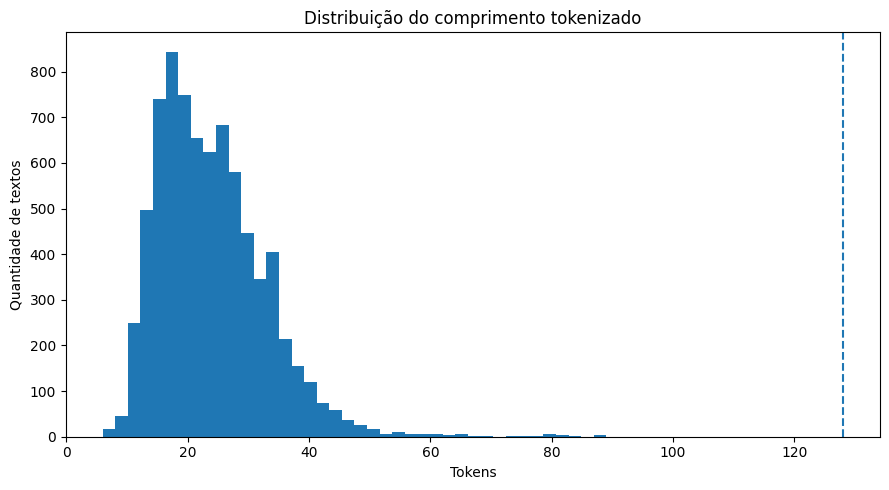

In [9]:

# 9. Visualização simples da distribuição de comprimento
plt.figure(figsize=(9, 5))
plt.hist(lengths_array, bins=40)
plt.axvline(MAX_LENGTH, linestyle="--")
plt.title("Distribuição do comprimento tokenizado")
plt.xlabel("Tokens")
plt.ylabel("Quantidade de textos")
plt.tight_layout()
plt.show()



## 6. Dataset Hugging Face

Somente duas colunas são fornecidas ao modelo:

- `text`
- `labels`

Os demais metadados permanecem fora da entrada do Transformer.


In [10]:

# 10. Construção dos datasets

train_dataset = Dataset.from_dict(
    {
        "text": [r["text"] for r in train_rows],
        "labels": [label2id[r["target_label"]] for r in train_rows],
    }
)

validation_dataset = Dataset.from_dict(
    {
        "text": [r["text"] for r in validation_rows],
        "labels": [label2id[r["target_label"]] for r in validation_rows],
    }
)


def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )


train_tokenized = train_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"],
    desc="Tokenizando train",
)

validation_tokenized = validation_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"],
    desc="Tokenizando validation",
)

print(train_tokenized)
print(validation_tokenized)


Tokenizando train:   0%|          | 0/6300 [00:00<?, ? examples/s]

Tokenizando validation:   0%|          | 0/1350 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 6300
})
Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1350
})



## 7. Modelo de classificação

O checkpoint pré-treinado é carregado com uma nova cabeça de classificação
para as 9 classes do KAMARA.


In [11]:

# 11. Modelo
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(EXPECTED_LABELS),
    label2id=label2id,
    id2label=id2label,
)

model.config.problem_type = "single_label_classification"

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Parâmetros totais    :", f"{total_params:,}")
print("Parâmetros treináveis:", f"{trainable_params:,}")


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Parâmetros totais    : 108,930,057
Parâmetros treináveis: 108,930,057



## 8. Métricas

A métrica primária é **Macro-F1**, porque queremos desempenho equilibrado entre
as nove classes. Também registramos Accuracy, Macro Precision, Macro Recall e
Weighted-F1.


In [12]:

# 12. Função de métricas

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_precision": precision_score(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0,
        ),
    }



## 9. Configuração do `Trainer`

A API do `TrainingArguments` mudou de nome em versões recentes de Transformers:
algumas versões usam `eval_strategy` e versões antigas usam
`evaluation_strategy`. A célula abaixo detecta automaticamente o parâmetro
disponível para manter o notebook mais robusto.


In [16]:

# 13. Diretórios de trabalho
WORK_ROOT = Path("/content/kamara_bertimbau_work")
CHECKPOINT_DIR = WORK_ROOT / "checkpoints"

EXPORT_ROOT = Path("/content/kamara_export")
ARTIFACT_DIR = EXPORT_ROOT / "ml" / "artifacts" / "nlp" / RUN_NAME
EVALUATION_DIR = EXPORT_ROOT / "ml" / "evaluation" / "nlp" / RUN_NAME

for directory in (CHECKPOINT_DIR, ARTIFACT_DIR, EVALUATION_DIR):
    directory.mkdir(parents=True, exist_ok=True)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8 if torch.cuda.is_available() else None,
)

# Calculate warmup steps
total_train_steps = int(len(train_tokenized) / (TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS) * NUM_EPOCHS)
calculated_warmup_steps = int(total_train_steps * WARMUP_RATIO)

training_args_kwargs = dict(
    output_dir=str(CHECKPOINT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=calculated_warmup_steps,

    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=25,

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",

    seed=SEED,
    data_seed=SEED,

    dataloader_num_workers=2
)

signature = inspect.signature(TrainingArguments.__init__)

if "eval_strategy" in signature.parameters:
    training_args_kwargs["eval_strategy"] = "epoch"
elif "evaluation_strategy" in signature.parameters:
    training_args_kwargs["evaluation_strategy"] = "epoch"
else:
    raise RuntimeError(
        "A versão instalada de Transformers não possui "
        "eval_strategy nem evaluation_strategy."
    )

training_args = TrainingArguments(**training_args_kwargs)

print(training_args)


TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=20260830,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=2,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_s

In [17]:

# 14. Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=validation_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=EARLY_STOPPING_PATIENCE
        )
    ],
)

print("Trainer pronto.")
print("TESTE NÃO FOI CARREGADO.")


Trainer pronto.
TESTE NÃO FOI CARREGADO.



# 10. Fine-tuning

Esta é a célula que efetivamente treina o BERTimbau.

O melhor checkpoint será determinado pelo maior **Macro-F1 na validation**.


In [18]:

# 15. TREINAMENTO
torch.cuda.empty_cache()

training_started_at = datetime.now(timezone.utc)
wall_start = time.time()

train_result = trainer.train()

wall_seconds = time.time() - wall_start
training_finished_at = datetime.now(timezone.utc)

print("\nTreinamento concluído.")
print("Tempo de parede (min):", round(wall_seconds / 60, 2))
print("Best checkpoint       :", trainer.state.best_model_checkpoint)
print("Best metric           :", trainer.state.best_metric)


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,0.296926,0.071297,0.986667,0.987001,0.986667,0.986677,0.986677
2,0.030413,0.015105,0.997037,0.997086,0.997037,0.997042,0.997042
3,0.012799,0.007066,0.998519,0.998528,0.998519,0.998519,0.998519


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Treinamento concluído.
Tempo de parede (min): 2.01
Best checkpoint       : /content/kamara_bertimbau_work/checkpoints/checkpoint-591
Best metric           : 0.9985185020574302



## 11. Avaliação na validation

Ainda **não** usamos o `test.jsonl`.


In [19]:

# 16. Avaliação agregada
validation_metrics = trainer.evaluate(
    eval_dataset=validation_tokenized,
    metric_key_prefix="validation",
)

print(json.dumps(validation_metrics, indent=2, ensure_ascii=False))


[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0.012799,0.007066,3,0.998519,0.998528,0.998519,0.998519,0.998519


{
  "validation_loss": 0.007066207937896252,
  "validation_accuracy": 0.9985185185185185,
  "validation_macro_precision": 0.9985283296541575,
  "validation_macro_recall": 0.9985185185185185,
  "validation_macro_f1": 0.9985185020574302,
  "validation_weighted_f1": 0.9985185020574302
}


In [20]:

# 17. Predições individuais
prediction_output = trainer.predict(
    validation_tokenized,
    metric_key_prefix="validation_predict",
)

logits = prediction_output.predictions
true_ids = prediction_output.label_ids
pred_ids = np.argmax(logits, axis=-1)

# Softmax estável
exp_logits = np.exp(logits - logits.max(axis=1, keepdims=True))
probabilities = exp_logits / exp_logits.sum(axis=1, keepdims=True)

true_labels = [id2label[int(i)] for i in true_ids]
pred_labels = [id2label[int(i)] for i in pred_ids]
pred_confidences = probabilities[
    np.arange(len(pred_ids)),
    pred_ids
]

accuracy = accuracy_score(true_labels, pred_labels)
macro_precision = precision_score(
    true_labels,
    pred_labels,
    labels=EXPECTED_LABELS,
    average="macro",
    zero_division=0,
)
macro_recall = recall_score(
    true_labels,
    pred_labels,
    labels=EXPECTED_LABELS,
    average="macro",
    zero_division=0,
)
macro_f1 = f1_score(
    true_labels,
    pred_labels,
    labels=EXPECTED_LABELS,
    average="macro",
    zero_division=0,
)
weighted_f1 = f1_score(
    true_labels,
    pred_labels,
    labels=EXPECTED_LABELS,
    average="weighted",
    zero_division=0,
)

print("Accuracy        :", round(accuracy, 6))
print("Macro Precision :", round(macro_precision, 6))
print("Macro Recall    :", round(macro_recall, 6))
print("Macro F1        :", round(macro_f1, 6))
print("Weighted F1     :", round(weighted_f1, 6))
print("Erros           :", int(np.sum(pred_ids != true_ids)))


Accuracy        : 0.998519
Macro Precision : 0.998528
Macro Recall    : 0.998519
Macro F1        : 0.998519
Weighted F1     : 0.998519
Erros           : 2



## 12. Métricas por classe


In [21]:

# 18. Classification report
report = classification_report(
    true_labels,
    pred_labels,
    labels=EXPECTED_LABELS,
    output_dict=True,
    zero_division=0,
)

per_class_rows = []

for label in EXPECTED_LABELS:
    metrics = report[label]
    per_class_rows.append(
        {
            "target_label": label,
            "precision": float(metrics["precision"]),
            "recall": float(metrics["recall"]),
            "f1_score": float(metrics["f1-score"]),
            "support": int(metrics["support"]),
        }
    )

per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df)


,target_label,precision,recall,f1_score,support
0,COBRADE_1_2_1_0_0,1.000000,1.000000,1.000000,150
1,COBRADE_1_2_2_0_0,1.000000,1.000000,1.000000,150
2,COBRADE_1_2_3_0_0,0.993377,1.000000,0.996678,150
3,COBRADE_1_4_1_3_1,1.000000,1.000000,1.000000,150
4,COBRADE_1_4_1_3_2,1.000000,0.993333,0.996656,150
5,COBRADE_2_3_1_1_0,0.993377,1.000000,0.996678,150
6,COBRADE_2_3_1_2_0,1.000000,1.000000,1.000000,150
7,OTHER,1.000000,1.000000,1.000000,150
8,INSUFFICIENT_INFO,1.000000,0.993333,0.996656,150



## 13. Matriz de confusão


,COBRADE_1_2_1_0_0,COBRADE_1_2_2_0_0,COBRADE_1_2_3_0_0,COBRADE_1_4_1_3_1,COBRADE_1_4_1_3_2,COBRADE_2_3_1_1_0,COBRADE_2_3_1_2_0,OTHER,INSUFFICIENT_INFO
COBRADE_1_2_1_0_0,150,0,0,0,0,0,0,0,0
COBRADE_1_2_2_0_0,0,150,0,0,0,0,0,0,0
COBRADE_1_2_3_0_0,0,0,150,0,0,0,0,0,0
COBRADE_1_4_1_3_1,0,0,0,150,0,0,0,0,0
COBRADE_1_4_1_3_2,0,0,0,0,149,1,0,0,0
COBRADE_2_3_1_1_0,0,0,0,0,0,150,0,0,0
COBRADE_2_3_1_2_0,0,0,0,0,0,0,150,0,0
OTHER,0,0,0,0,0,0,0,150,0
INSUFFICIENT_INFO,0,0,1,0,0,0,0,0,149


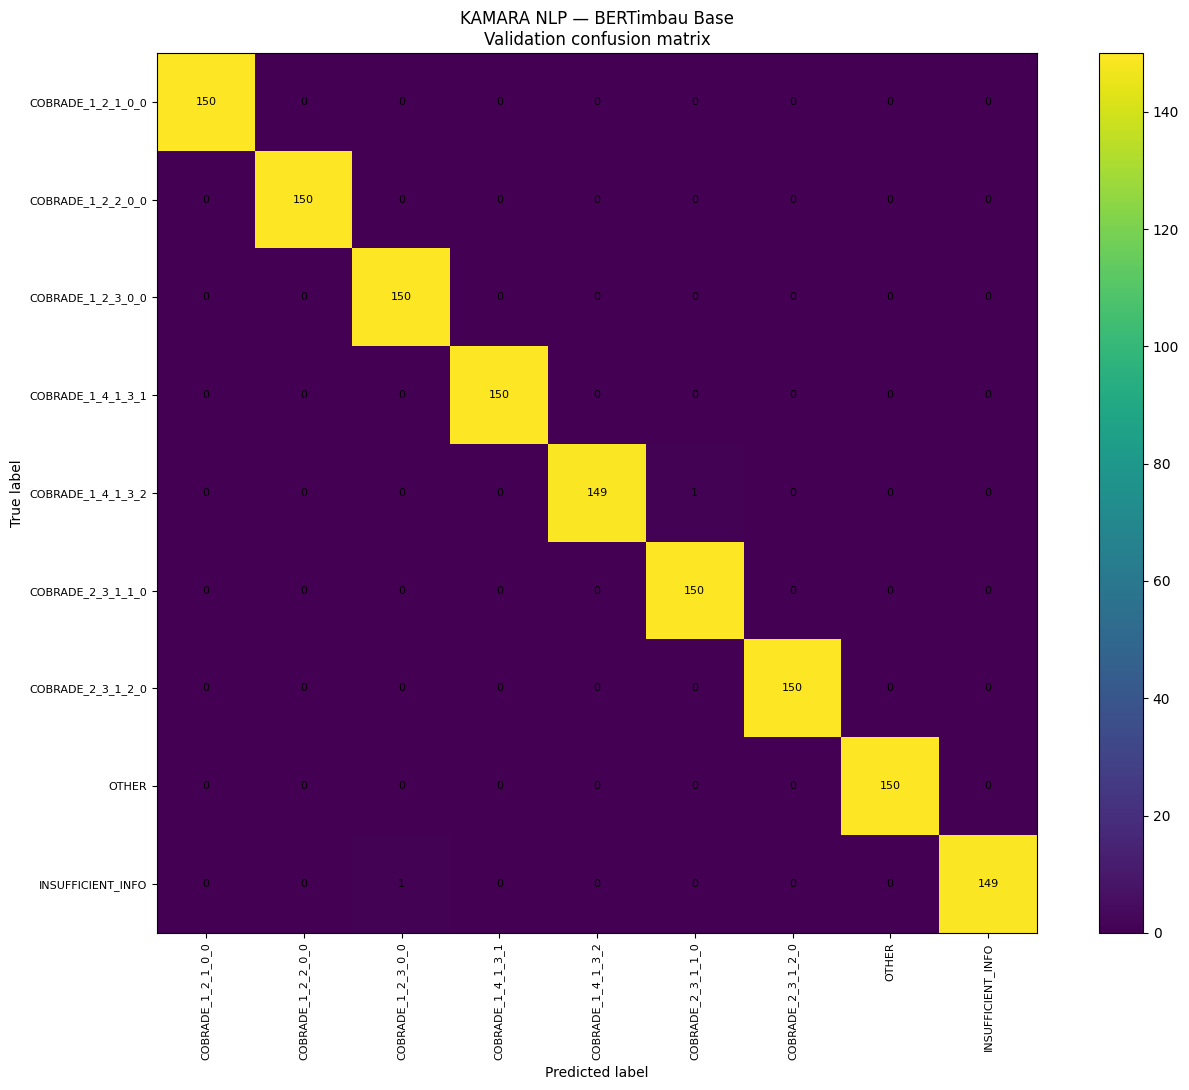

In [22]:

# 19. Matriz de confusão
cm = confusion_matrix(
    true_labels,
    pred_labels,
    labels=EXPECTED_LABELS,
)

cm_df = pd.DataFrame(
    cm,
    index=EXPECTED_LABELS,
    columns=EXPECTED_LABELS,
)

display(cm_df)

plt.figure(figsize=(14, 11))
plt.imshow(cm)
plt.title("KAMARA NLP — BERTimbau Base\nValidation confusion matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks(
    np.arange(len(EXPECTED_LABELS)),
    EXPECTED_LABELS,
    rotation=90,
    fontsize=8,
)
plt.yticks(
    np.arange(len(EXPECTED_LABELS)),
    EXPECTED_LABELS,
    fontsize=8,
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=8,
        )

plt.colorbar()
plt.tight_layout()
plt.show()



## 14. Análise de erros

Além da classe verdadeira/predita, preservamos `linguistic_profile`,
`difficulty` e `scenario_family` apenas para **análise pós-hoc**. Esses campos
não foram fornecidos ao modelo.


In [23]:

# 20. DataFrame de predições
prediction_rows = []

for source_row, true_label, pred_label, confidence in zip(
    validation_rows,
    true_labels,
    pred_labels,
    pred_confidences,
):
    prediction_rows.append(
        {
            "sample_id": source_row["sample_id"],
            "true_label": true_label,
            "predicted_label": pred_label,
            "correct": int(true_label == pred_label),
            "predicted_probability": float(confidence),
            "linguistic_profile": source_row.get("linguistic_profile"),
            "difficulty": source_row.get("difficulty"),
            "scenario_family": source_row.get("scenario_family"),
            "text": source_row["text"],
        }
    )

predictions_df = pd.DataFrame(prediction_rows)
errors_df = predictions_df[predictions_df["correct"] == 0].copy()

print("Predições:", len(predictions_df))
print("Erros    :", len(errors_df))

if len(errors_df):
    display(
        errors_df.sort_values(
            "predicted_probability",
            ascending=False,
        )
    )
else:
    print("Nenhum erro na validation.")


Predições: 1350
Erros    : 2


,sample_id,true_label,predicted_label,correct,predicted_probability,linguistic_profile,difficulty,scenario_family,text
1177,insufficient_info_0867,INSUFFICIENT_INFO,COBRADE_1_2_3_0_0,0,0.606895,profanity_emotional,typical,very_short_vague,caralho a agua aumentou
742,cobrade_1_4_1_3_2_0966,COBRADE_1_4_1_3_2,COBRADE_2_3_1_1_0,0,0.459841,mixed_noisy,intermediate,farm_secondary_forest,PQP AQ TEM FOGO EM VEGETACAO SECUNDARIA ENTRE ...



## 15. Histórico de treinamento


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_macro_precision,eval_macro_recall,eval_macro_f1,...,train_loss,validation_loss,validation_accuracy,validation_macro_precision,validation_macro_recall,validation_macro_f1,validation_weighted_f1,validation_runtime,validation_samples_per_second,validation_steps_per_second
8,0.173319,5.450697,1.473684e-05,1.015228,200,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.111966,0.801193,1.379699e-05,1.142132,225,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,0.071194,0.713238,1.285714e-05,1.269036,250,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,0.075384,0.231350,1.191729e-05,1.395939,275,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,0.038853,0.196881,1.097744e-05,1.522843,300,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,0.045051,0.267520,1.003759e-05,1.649746,325,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,0.032741,3.014742,9.097744e-06,1.776650,350,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,0.030413,0.123418,8.157895e-06,1.903553,375,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,NaN,NaN,NaN,2.000000,394,0.015105,0.997037,0.997086,0.997037,0.997042,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,0.028550,0.120968,7.218045e-06,2.030457,400,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


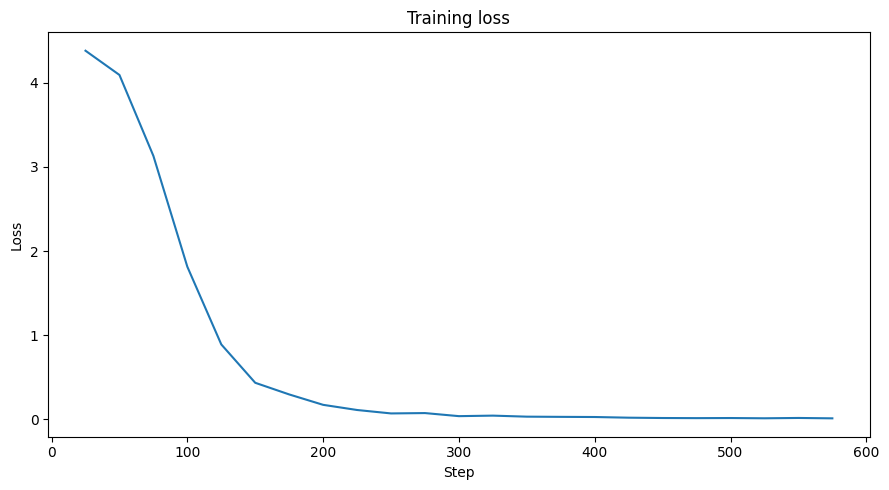

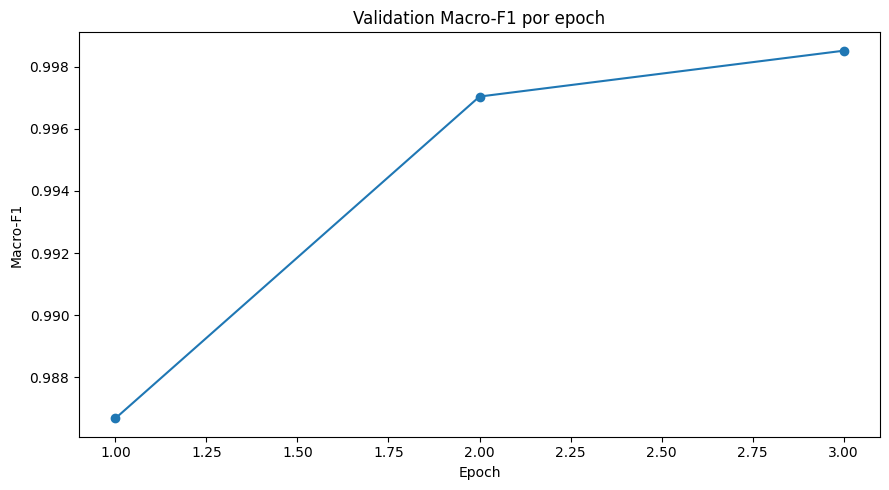

In [24]:

# 21. Histórico de logs
training_history_df = pd.DataFrame(trainer.state.log_history)

display(training_history_df.tail(20))

if "loss" in training_history_df.columns:
    train_log = training_history_df.dropna(subset=["loss"])
    if len(train_log):
        plt.figure(figsize=(9, 5))
        plt.plot(train_log["step"], train_log["loss"])
        plt.title("Training loss")
        plt.xlabel("Step")
        plt.ylabel("Loss")
        plt.tight_layout()
        plt.show()

eval_rows = training_history_df.dropna(
    subset=["eval_macro_f1"]
    if "eval_macro_f1" in training_history_df.columns
    else []
)

if len(eval_rows) and "eval_macro_f1" in eval_rows.columns:
    plt.figure(figsize=(9, 5))
    plt.plot(eval_rows["epoch"], eval_rows["eval_macro_f1"], marker="o")
    plt.title("Validation Macro-F1 por epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Macro-F1")
    plt.tight_layout()
    plt.show()



## 16. Comparação preliminar com o baseline clássico

Resultado previamente obtido na mesma validation:

- TF-IDF + Logistic Regression
- Accuracy: `0.9963`
- Macro-F1: `0.9963`

A comparação aqui ainda é **sintética**. Um valor maior não prova melhor
generalização para relatos reais.


In [25]:

# 22. Comparação validation
comparison_df = pd.DataFrame(
    [
        {
            "model": "TF-IDF + Logistic Regression",
            "accuracy": 0.9963,
            "macro_f1": 0.9963,
        },
        {
            "model": "BERTimbau Base",
            "accuracy": accuracy,
            "macro_f1": macro_f1,
        },
    ]
)

display(comparison_df)


,model,accuracy,macro_f1
0,TF-IDF + Logistic Regression,0.996300,0.996300
1,BERTimbau Base,0.998519,0.998519



# 17. Exportação dos artefatos

Será criado um ZIP já com a estrutura esperada do repositório:

```text
ml/
├── artifacts/nlp/kamara_bertimbau_v1/
└── evaluation/nlp/kamara_bertimbau_v1/
```

Depois de baixar e extrair o ZIP na raiz do projeto, revise os arquivos antes de
versioná-los.


In [26]:

# 23. Salvar modelo/tokenizer
trainer.save_model(str(ARTIFACT_DIR))
tokenizer.save_pretrained(str(ARTIFACT_DIR))

print("Modelo salvo em:", ARTIFACT_DIR)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo salvo em: /content/kamara_export/ml/artifacts/nlp/kamara_bertimbau_v1


In [27]:

# 24. Salvar métricas, matrizes, predições, erros e histórico

metrics_validation = {
    "split": "validation",
    "records": len(validation_rows),
    "accuracy": float(accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "errors": int(np.sum(pred_ids != true_ids)),
    "labels": EXPECTED_LABELS,
}

with (EVALUATION_DIR / "metrics_validation.json").open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metrics_validation,
        f,
        ensure_ascii=False,
        indent=2,
    )
    f.write("\n")

per_class_df.to_csv(
    EVALUATION_DIR / "per_class_metrics_validation.csv",
    index=False,
)

cm_df.to_csv(
    EVALUATION_DIR / "confusion_matrix_validation.csv",
    index=True,
    index_label="true_label",
)

predictions_df.to_csv(
    EVALUATION_DIR / "predictions_validation.csv",
    index=False,
)

errors_df.to_csv(
    EVALUATION_DIR / "errors_validation.csv",
    index=False,
)

training_history_df.to_csv(
    EVALUATION_DIR / "training_history.csv",
    index=False,
)

# PNG da matriz
fig, ax = plt.subplots(figsize=(14, 11))
image = ax.imshow(cm)
ax.set_title(
    "KAMARA NLP — BERTimbau Base\nValidation confusion matrix"
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks(np.arange(len(EXPECTED_LABELS)))
ax.set_yticks(np.arange(len(EXPECTED_LABELS)))
ax.set_xticklabels(EXPECTED_LABELS, rotation=90, fontsize=8)
ax.set_yticklabels(EXPECTED_LABELS, fontsize=8)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=8,
        )

fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(
    EVALUATION_DIR / "confusion_matrix_validation.png",
    dpi=180,
    bbox_inches="tight",
)
plt.close(fig)

print("Arquivos de avaliação salvos em:", EVALUATION_DIR)


Arquivos de avaliação salvos em: /content/kamara_export/ml/evaluation/nlp/kamara_bertimbau_v1


In [28]:

# 25. Metadados completos do experimento

def current_gpu_info():
    if not torch.cuda.is_available():
        return None
    props = torch.cuda.get_device_properties(0)
    return {
        "name": torch.cuda.get_device_name(0),
        "total_memory_gb": round(props.total_memory / 1024**3, 4),
        "compute_capability": list(torch.cuda.get_device_capability(0)),
    }


run_metadata = {
    "run_name": RUN_NAME,
    "task": "multiclass_text_classification",
    "model_base": MODEL_NAME,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "training_started_at_utc": training_started_at.isoformat(),
    "training_finished_at_utc": training_finished_at.isoformat(),
    "wall_time_seconds": wall_seconds,

    "environment": {
        "python": sys.version,
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "datasets": datasets.__version__,
        "accelerate": __import__("accelerate").__version__,
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "gpu": current_gpu_info(),
    },

    "data": {
        "train": {
            "filename": "train.jsonl",
            "records": len(train_rows),
            "sha256": TRAIN_SHA256,
        },
        "validation": {
            "filename": "validation.jsonl",
            "records": len(validation_rows),
            "sha256": VALIDATION_SHA256,
        },
        "test": {
            "used": False,
            "note": "test.jsonl was intentionally not uploaded or evaluated.",
        },
    },

    "model_input": ["text"],
    "target": "target_label",

    "excluded_from_model_input": [
        "sample_id",
        "cobrade_code",
        "scenario_family",
        "linguistic_profile",
        "noise_features",
        "difficulty",
        "generation_batch",
        "prompt_version",
        "generator_model",
        "synthetic",
        "review_status",
        "review_notes",
        "split",
        "similarity_group_id",
    ],

    "label2id": label2id,
    "id2label": {
        str(key): value
        for key, value in id2label.items()
    },

    "hyperparameters": {
        "max_length": MAX_LENGTH,
        "learning_rate": LEARNING_RATE,
        "num_train_epochs": NUM_EPOCHS,
        "weight_decay": WEIGHT_DECAY,
        "warmup_ratio": WARMUP_RATIO,
        "per_device_train_batch_size": TRAIN_BATCH_SIZE,
        "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
        "effective_train_batch_size": EFFECTIVE_BATCH_SIZE,
        "per_device_eval_batch_size": EVAL_BATCH_SIZE,
        "fp16": bool(torch.cuda.is_available()),
        "seed": SEED,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "metric_for_best_model": "macro_f1",
    },

    "token_length_diagnostics": summary,

    "trainer": {
        "best_model_checkpoint": trainer.state.best_model_checkpoint,
        "best_metric": trainer.state.best_metric,
        "global_step": trainer.state.global_step,
        "train_result_metrics": {
            key: (
                float(value)
                if isinstance(value, (int, float, np.number))
                else value
            )
            for key, value in train_result.metrics.items()
        },
    },

    "validation_metrics": metrics_validation,

    "baseline_reference": {
        "model": "TF-IDF + Logistic Regression",
        "validation_accuracy": 0.9963,
        "validation_macro_f1": 0.9963,
        "shortcut_stress_test_macro_f1": 0.9948,
    },

    "notes": [
        "Only text was used as model input.",
        "The synthetic test split was not used during training or validation.",
        "Near-duplicate groups had previously been kept within a single split.",
        "Synthetic validation performance must not be interpreted as real-world generalization.",
        "Independent manual/external evaluation remains required.",
    ],
}

with (ARTIFACT_DIR / "run_metadata.json").open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        run_metadata,
        f,
        ensure_ascii=False,
        indent=2,
    )
    f.write("\n")

print(json.dumps(
    {
        "best_checkpoint": trainer.state.best_model_checkpoint,
        "best_metric": trainer.state.best_metric,
        "validation_macro_f1": macro_f1,
        "validation_accuracy": accuracy,
        "test_used": False,
    },
    indent=2,
))


{
  "best_checkpoint": "/content/kamara_bertimbau_work/checkpoints/checkpoint-591",
  "best_metric": 0.9985185020574302,
  "validation_macro_f1": 0.9985185020574302,
  "validation_accuracy": 0.9985185185185185,
  "test_used": false
}



## 18. Checklist científico antes de baixar

Confirme:

- [ ] GPU foi registrada;
- [ ] `train.jsonl` = 6.300 registros;
- [ ] `validation.jsonl` = 1.350 registros;
- [ ] cada classe tem 700/150;
- [ ] `test.jsonl` não foi usado;
- [ ] melhor checkpoint foi selecionado por Macro-F1;
- [ ] métricas por classe foram salvas;
- [ ] matriz de confusão foi salva;
- [ ] predições e erros foram salvos;
- [ ] `run_metadata.json` foi criado;
- [ ] notebook executado será baixado separadamente.


In [29]:

# 26. Conferência final da estrutura exportada

for path in sorted(EXPORT_ROOT.rglob("*")):
    if path.is_file():
        print(path.relative_to(EXPORT_ROOT))


ml/artifacts/nlp/kamara_bertimbau_v1/config.json
ml/artifacts/nlp/kamara_bertimbau_v1/model.safetensors
ml/artifacts/nlp/kamara_bertimbau_v1/run_metadata.json
ml/artifacts/nlp/kamara_bertimbau_v1/tokenizer.json
ml/artifacts/nlp/kamara_bertimbau_v1/tokenizer_config.json
ml/artifacts/nlp/kamara_bertimbau_v1/training_args.bin
ml/evaluation/nlp/kamara_bertimbau_v1/confusion_matrix_validation.csv
ml/evaluation/nlp/kamara_bertimbau_v1/confusion_matrix_validation.png
ml/evaluation/nlp/kamara_bertimbau_v1/errors_validation.csv
ml/evaluation/nlp/kamara_bertimbau_v1/metrics_validation.json
ml/evaluation/nlp/kamara_bertimbau_v1/per_class_metrics_validation.csv
ml/evaluation/nlp/kamara_bertimbau_v1/predictions_validation.csv
ml/evaluation/nlp/kamara_bertimbau_v1/training_history.csv


In [30]:

# 27. Criar ZIP para download
ZIP_BASE = Path("/content/kamara_bertimbau_v1_export")

zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=EXPORT_ROOT,
)

print("ZIP criado:", zip_path)
print("Tamanho (MB):", round(Path(zip_path).stat().st_size / 1024**2, 2))


ZIP criado: /content/kamara_bertimbau_v1_export.zip
Tamanho (MB): 385.96


In [31]:

# 28. Download dos artefatos/resultados
from google.colab import files

files.download("/content/kamara_bertimbau_v1_export.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# 19. Depois do Colab

Baixe também este notebook executado:

**Arquivo → Fazer download → Fazer download do .ipynb**

No repositório local, salve como:

```text
ml/notebooks/nlp/01_train_bertimbau_baseline.ipynb
```

Extraia o ZIP na raiz do repositório. A estrutura exportada já contém:

```text
ml/artifacts/nlp/kamara_bertimbau_v1/
ml/evaluation/nlp/kamara_bertimbau_v1/
```

### Próximas etapas após este experimento

1. analisar métricas e erros do BERTimbau na validation;
2. comparar com TF-IDF + Logistic Regression;
3. decidir se ajustes de modelagem são realmente necessários;
4. congelar a configuração escolhida;
5. **só então** avaliar uma vez no `test.jsonl` sintético;
6. avaliar em conjunto manual/externo independente;
7. escolher o modelo de produção;
8. integrar no FastAPI;
9. posteriormente avaliar fusão texto + visão.

### Referência do modelo

BERTimbau Base — Souza, Nogueira e Lotufo (2020), modelo pré-treinado para
português brasileiro.

Checkpoint utilizado:

`neuralmind/bert-base-portuguese-cased`
